In [24]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

def load_and_analyze_data(dmm_filename, zero_traj_filename):
    dmm_data = json.load(open(dmm_filename))
    zero_traj_data = json.load(open(zero_traj_filename))

    # Convert the data to pandas DataFrames
    df1 = pd.DataFrame(dmm_data)
    df2 = pd.DataFrame(zero_traj_data)

    if 'gui.evals_opt' in df1.columns:
        df1.rename(columns={'gui.evals_opt': 'TaskSolGui.evals_opt'}, inplace=True)
    
    if 'gui.evals_opt' in df2.columns:
        df2.rename(columns={'gui.evals_opt': 'TaskSolGui.evals_opt'}, inplace=True)
        
    if 'gui.iterations' in df1.columns:
        df1.rename(columns={'gui.iteration_opt': 'TaskSolGui.iteration_opt'}, inplace=True)
    
    if 'gui.iterations' in df2.columns:
        df2.rename(columns={'gui.iteration_opt': 'TaskSolGui.iteration_opt'}, inplace=True)
        
    

    # Analyze the data (mean, std, etc.)
    print('DMM Trajectory Evaluation:')
    print(df1.describe())
    print('Zero Traj Trajectory Evaluation:')
    print(df2.describe())

    return df1, df2
    



In [25]:
dmm_eval_filename = 'eval_data/dmm_iter_0_drop_start_evals.json'
zero_traj_eval_filename = 'eval_data/dmm_mixed_drop_start_evals.json'

dmm_iter_filename = 'eval_data/dmm_iter_0_drop_start_iterations.json'
zero_traj_iter_filename = 'eval_data/dmm_mixed_drop_start_iterations.json'

In [42]:
dmm_eval_filename = 'eval_data/dmm_iter_0_pick_start_evals.json'
zero_traj_eval_filename = 'eval_data/dmm_mixed_pick_start_evals.json'

dmm_iter_filename = 'eval_data/dmm_iter_0_pick_start_iterations.json'
zero_traj_iter_filename = 'eval_data/dmm_mixed_pick_start_iterations.json'

In [58]:
dmm_eval_filename = 'eval_data/dmm_iter_0_pick_start_evals.json'
zero_traj_eval_filename = 'eval_data/de_test_evals.json'

dmm_iter_filename = 'eval_data/dmm_iter_0_pick_start_iterations.json'
zero_traj_iter_filename = 'eval_data/de_test_iterations.json'

In [60]:
dmm_df, zero_traj_df = load_and_analyze_data(dmm_eval_filename, zero_traj_eval_filename)

DMM Trajectory Evaluation:
       TaskSolGui.evals_opt
count           1621.000000
mean               0.085420
std                0.264262
min                0.002665
25%                0.010322
50%                0.016727
75%                0.036852
max                7.972712
Zero Traj Trajectory Evaluation:
       TaskSolGui.evals_opt
count           1621.000000
mean               0.133862
std                0.869661
min                0.002082
25%                0.010145
50%                0.016334
75%                0.033144
max               13.796804


In [61]:
# count how many times the eval is over the threshold and what percentage of the time it is over the threshold
threshold = 0.1
dmm_over_threshold_count = (dmm_df['TaskSolGui.evals_opt'] > threshold).sum()
dmm_over_threshold_percentage = (dmm_over_threshold_count / len(dmm_df)) * 100

zero_traj_over_threshold_count = (zero_traj_df['TaskSolGui.evals_opt'] > threshold).sum()
zero_traj_over_threshold_percentage = (zero_traj_over_threshold_count / len(zero_traj_df)) * 100

print(f"DMM over {threshold} count: {dmm_over_threshold_count}, percentage: {dmm_over_threshold_percentage:.2f}%")
print(f"Zero Trajectory over {threshold} count: {zero_traj_over_threshold_count}, percentage: {zero_traj_over_threshold_percentage:.2f}%")


DMM over 0.1 count: 267, percentage: 16.47%
Zero Trajectory over 0.1 count: 273, percentage: 16.84%


In [62]:
dmm_iter_df, zero_traj_iter_df = load_and_analyze_data(dmm_iter_filename, zero_traj_iter_filename)

DMM Trajectory Evaluation:
       gui.iteration_opt
count        1621.000000
mean            9.778532
std            12.710293
min             1.000000
25%             5.000000
50%             6.000000
75%             9.000000
max           180.000000
Zero Traj Trajectory Evaluation:
       gui.iteration_opt
count        1621.000000
mean            8.026527
std            12.557469
min             1.000000
25%             3.000000
50%             4.000000
75%             7.000000
max           157.000000


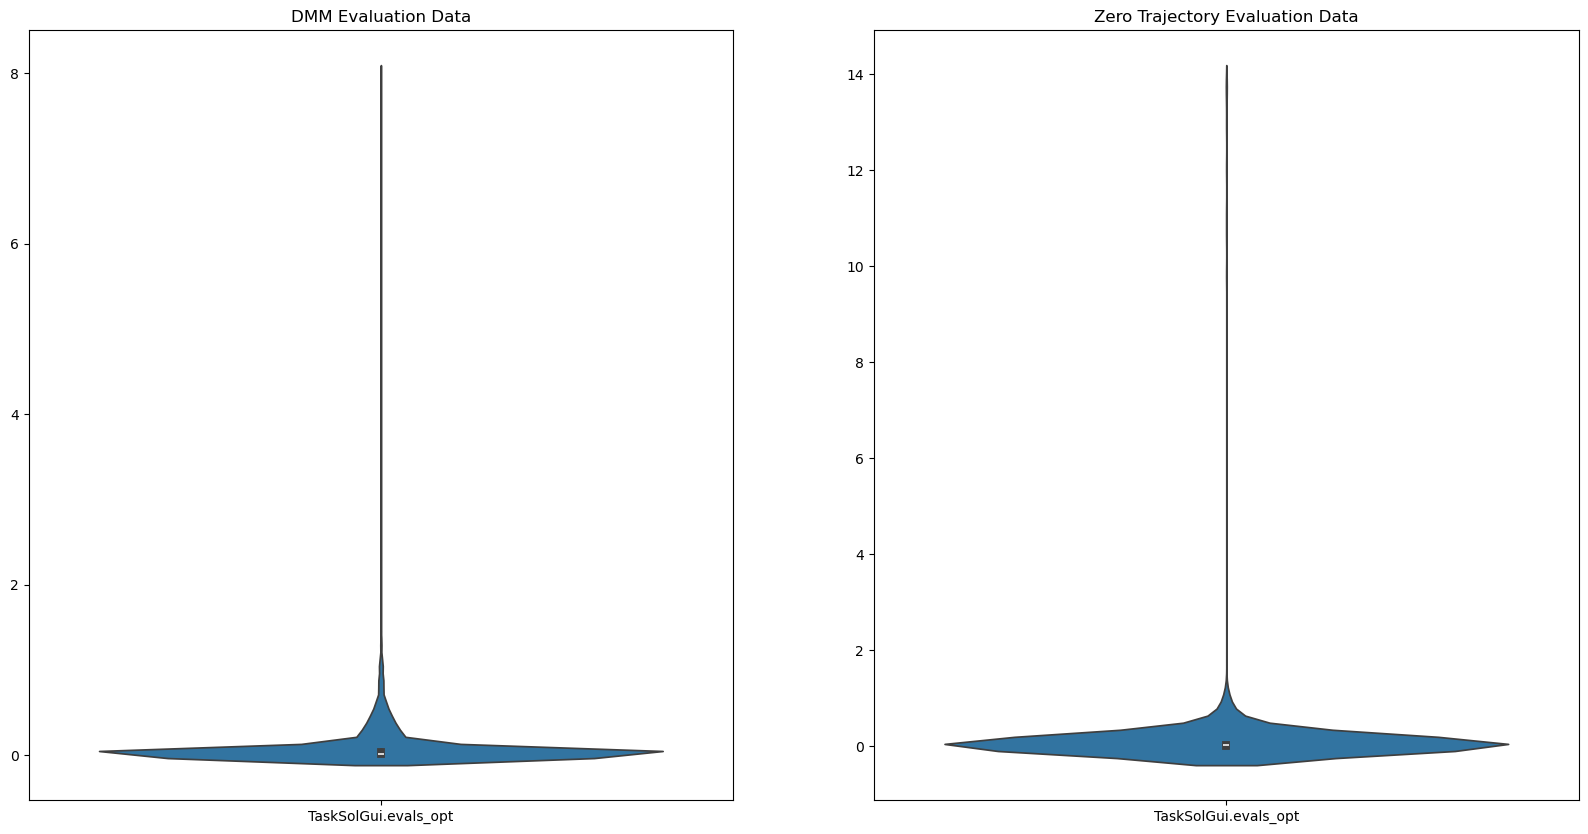

In [63]:
# visualize the data using violin plots comparing the two methods
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sns.violinplot(data=dmm_df, ax=ax[0])
ax[0].set_title('DMM Evaluation Data')
sns.violinplot(data=zero_traj_df, ax=ax[1])
ax[1].set_title('Zero Trajectory Evaluation Data')
plt.show()


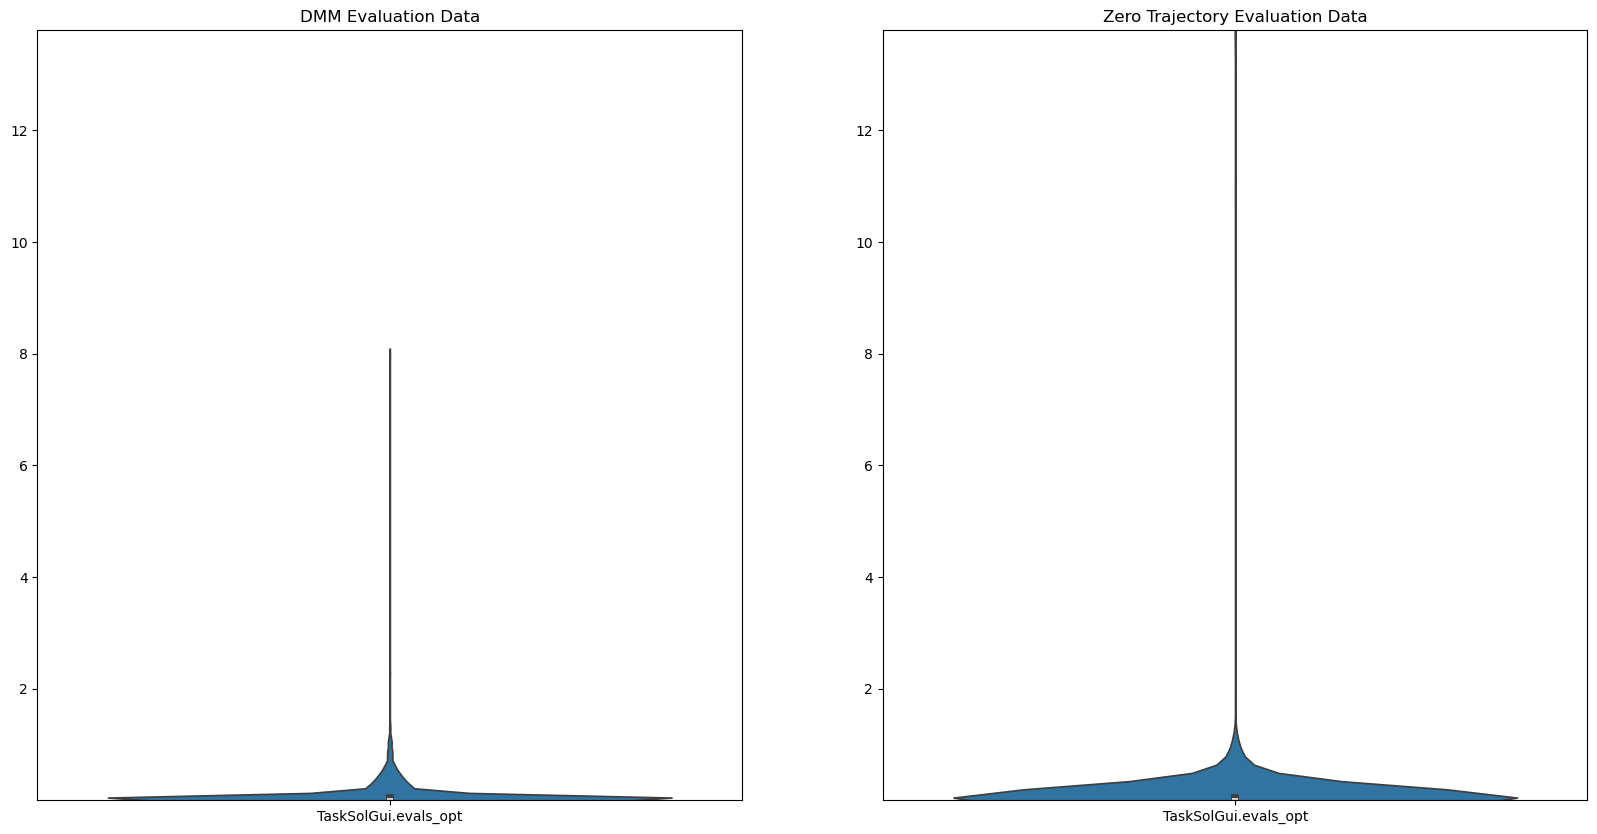

In [64]:
# visualize the data using violin plots comparing the two methods
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# Plot the violin plots
sns.violinplot(data=dmm_df, ax=ax[0])
ax[0].set_title('DMM Evaluation Data')
sns.violinplot(data=zero_traj_df, ax=ax[1])
ax[1].set_title('Zero Trajectory Evaluation Data')

# Determine the y-axis limits
min_val = min(dmm_df.min().min(), zero_traj_df.min().min())
max_val = max(dmm_df.max().max(), zero_traj_df.max().max())

# Set the same y-axis limits for both plots
ax[0].set_ylim(min_val, max_val)
ax[1].set_ylim(min_val, max_val)

# Show the plots
plt.show()

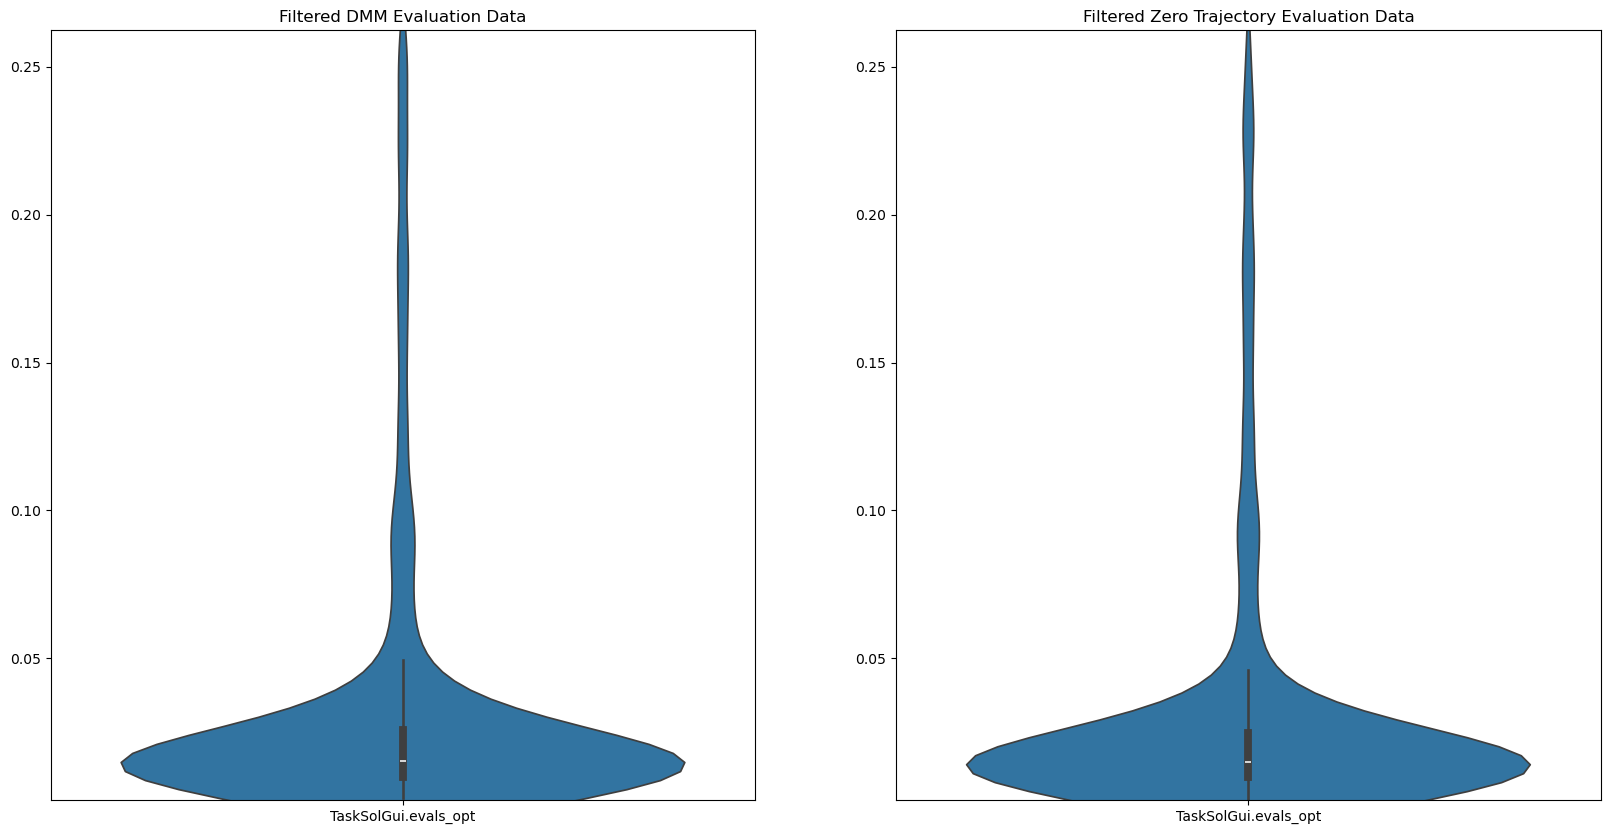

In [65]:
# Calculate the 10th and 90th percentiles for each dataset
dmm_lower_quantile = dmm_df.quantile(0)
dmm_upper_quantile = dmm_df.quantile(0.9)
zero_traj_lower_quantile = zero_traj_df.quantile(0)
zero_traj_upper_quantile = zero_traj_df.quantile(0.9)

# Filter the data to remove the extreme values
filtered_dmm_df = dmm_df[(dmm_df >= dmm_lower_quantile) & (dmm_df <= dmm_upper_quantile)].dropna()
filtered_zero_traj_df = zero_traj_df[(zero_traj_df >= zero_traj_lower_quantile) & (zero_traj_df <= zero_traj_upper_quantile)].dropna()

# Plot the filtered data using violin plots
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sns.violinplot(data=filtered_dmm_df, ax=ax[0])
ax[0].set_title('Filtered DMM Evaluation Data')
sns.violinplot(data=filtered_zero_traj_df, ax=ax[1])
ax[1].set_title('Filtered Zero Trajectory Evaluation Data')

# Set the same y-axis limits for both plots
y_min = min(filtered_dmm_df.min().min(), filtered_zero_traj_df.min().min())
y_max = max(filtered_dmm_df.max().max(), filtered_zero_traj_df.max().max())
ax[0].set_ylim(y_min, y_max)
ax[1].set_ylim(y_min, y_max)

plt.show()

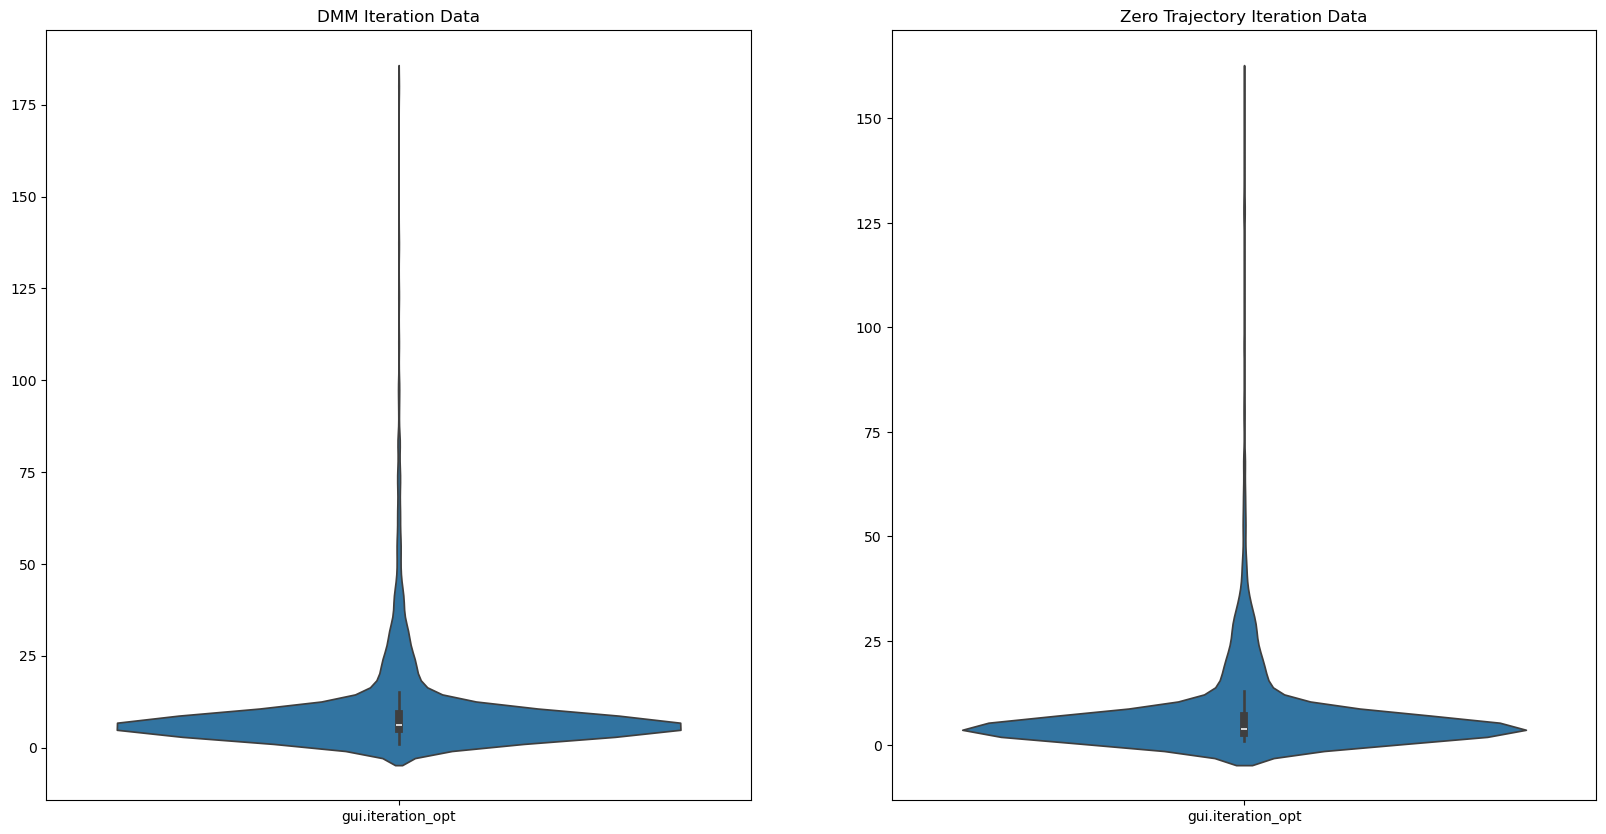

In [66]:
# compare the distributions of the number of iterations required for the two methods using violin plots
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sns.violinplot(data=dmm_iter_df, ax=ax[0])
ax[0].set_title('DMM Iteration Data')
sns.violinplot(data=zero_traj_iter_df, ax=ax[1])
ax[1].set_title('Zero Trajectory Iteration Data')
plt.show()


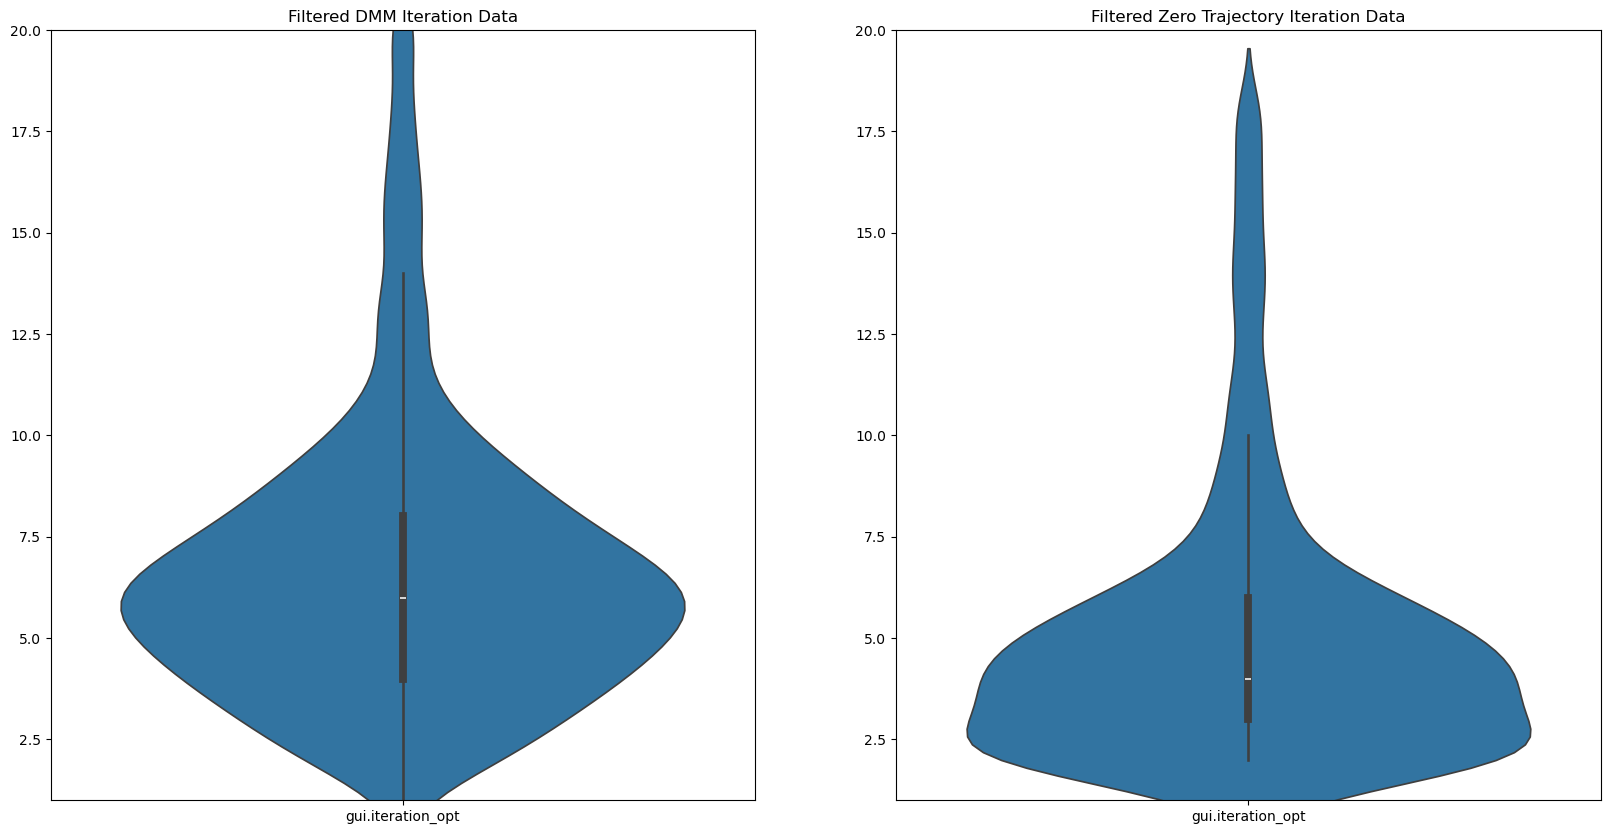

In [67]:
# Calculate the 10th and 90th percentiles for the iteration data
dmm_iter_lower_quantile = dmm_iter_df.quantile(0)
dmm_iter_upper_quantile = dmm_iter_df.quantile(0.9)
zero_traj_iter_lower_quantile = zero_traj_iter_df.quantile(0.1)
zero_traj_iter_upper_quantile = zero_traj_iter_df.quantile(0.9)

# Filter the iteration data to remove the extreme values
filtered_dmm_iter_df = dmm_iter_df[(dmm_iter_df >= dmm_iter_lower_quantile) & (dmm_iter_df <= dmm_iter_upper_quantile)].dropna()
filtered_zero_traj_iter_df = zero_traj_iter_df[(zero_traj_iter_df >= zero_traj_iter_lower_quantile) & (zero_traj_iter_df <= zero_traj_iter_upper_quantile)].dropna()

# Plot the filtered iteration data using violin plots
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sns.violinplot(data=filtered_dmm_iter_df, ax=ax[0])
ax[0].set_title('Filtered DMM Iteration Data')
sns.violinplot(data=filtered_zero_traj_iter_df, ax=ax[1])
ax[1].set_title('Filtered Zero Trajectory Iteration Data')

# Set the same y-axis limits for both plots
y_min_iter = min(filtered_dmm_iter_df.min().min(), filtered_zero_traj_iter_df.min().min())
y_max_iter = max(filtered_dmm_iter_df.max().max(), filtered_zero_traj_iter_df.max().max())
ax[0].set_ylim(y_min_iter, y_max_iter)
ax[1].set_ylim(y_min_iter, y_max_iter)

plt.show()